# SOLID Principles

**SOLID** is a set of five design principles for object-oriented code. They help you write code that is easy to extend without breaking what already works. The principles are guidelines, not laws: apply them when a design starts to hurt.

**After this lesson you can:**

1. State the five principles and the problem that each one prevents.
2. Recognise violations in real code.
3. Refactor code towards each principle with Python features (ABCs, `Protocol`, dependency injection).

| Letter | Principle | Short version |
| :-: | :--- | :--- |
| **S** | Single Responsibility | a class has one reason to change |
| **O** | Open/Closed | add behaviour by adding code, not by editing old code |
| **L** | Liskov Substitution | a subclass must work wherever its base class works |
| **I** | Interface Segregation | small, focused interfaces |
| **D** | Dependency Inversion | depend on abstractions, not on concrete classes |

## 1. S: Single Responsibility

The class below loads data, computes a report **and** writes a file. A change of the file format, of the database or of the report logic all touch the same class.

In [1]:
import csv
import io
import json
from abc import ABC, abstractmethod
from typing import Protocol

class SalesReportBad:
    def run(self, rows: list[dict]) -> str:
        total = sum(r["amount"] for r in rows)                      # business logic
        by_city: dict[str, float] = {}
        for r in rows:
            by_city[r["city"]] = by_city.get(r["city"], 0) + r["amount"]
        out = io.StringIO()                                          # formatting
        writer = csv.writer(out)
        writer.writerow(["city", "amount"])
        writer.writerows(by_city.items())
        writer.writerow(["TOTAL", total])
        return out.getvalue()

rows = [{"city": "Ankara", "amount": 120.0}, {"city": "İzmir", "amount": 80.0}, {"city": "Ankara", "amount": 50.0}]
print(SalesReportBad().run(rows))

city,amount
Ankara,170.0
İzmir,80.0
TOTAL,250.0



In [2]:
class SalesSummary:                       # responsibility 1: compute
    @staticmethod
    def by_city(rows: list[dict]) -> dict[str, float]:
        result: dict[str, float] = {}
        for r in rows:
            result[r["city"]] = result.get(r["city"], 0) + r["amount"]
        return result

class CsvExporter:                        # responsibility 2: format
    def export(self, summary: dict[str, float]) -> str:
        out = io.StringIO()
        w = csv.writer(out)
        w.writerow(["city", "amount"])
        w.writerows(summary.items())
        w.writerow(["TOTAL", sum(summary.values())])
        return out.getvalue()

print(CsvExporter().export(SalesSummary.by_city(rows)))

city,amount
Ankara,170.0
İzmir,80.0
TOTAL,250.0



## 2. O: Open/Closed

A new output format should not require edits in old, tested code. Define an abstraction (`Exporter`) and add a new class for each format. The report code is **closed for modification** but **open for extension**.

In [3]:
class Exporter(ABC):
    @abstractmethod
    def export(self, summary: dict[str, float]) -> str: ...

class CsvExport(Exporter):
    def export(self, summary):
        return CsvExporter().export(summary)

class JsonExport(Exporter):
    def export(self, summary):
        return json.dumps({"by_city": summary, "total": sum(summary.values())}, ensure_ascii=False)

class MarkdownExport(Exporter):           # added later; no other code changed
    def export(self, summary):
        lines = ["| city | amount |", "| --- | ---: |"] + [f"| {c} | {a:.2f} |" for c, a in summary.items()]
        return "\n".join(lines)

def build_report(rows: list[dict], exporter: Exporter) -> str:
    return exporter.export(SalesSummary.by_city(rows))

for exp in (JsonExport(), MarkdownExport()):
    print(build_report(rows, exp), "\n")

{"by_city": {"Ankara": 170.0, "İzmir": 80.0}, "total": 250.0} 

| city | amount |
| --- | ---: |
| Ankara | 170.00 |
| İzmir | 80.00 | 



## 3. L: Liskov Substitution

Code that works with a base class must also work with every subclass. A subclass must not **strengthen** the requirements on its inputs or **weaken** the promises of its outputs. The classic violation: a `Square` subclass of `Rectangle` that breaks code which sets width and height independently.

In [4]:
class Rectangle:
    def __init__(self, w: float, h: float):
        self.w, self.h = w, h

    def set_width(self, w: float):
        self.w = w

    def area(self) -> float:
        return self.w * self.h

class Square(Rectangle):
    def __init__(self, side: float):
        super().__init__(side, side)

    def set_width(self, w: float):        # keeps the square a square...
        self.w = self.h = w               # ...but changes the height as a side effect

def stretch(shape: Rectangle) -> float:
    shape.set_width(10)                   # the caller expects only the width to change
    return shape.area()

print("Rectangle(2, 5) stretched:", stretch(Rectangle(2, 5)), "(expected 10 * 5 = 50)")
print("Square(5) stretched      :", stretch(Square(5)), "(expected 10 * 5 = 50, got 100: LSP violation)")

Rectangle(2, 5) stretched: 50 (expected 10 * 5 = 50)
Square(5) stretched      : 100 (expected 10 * 5 = 50, got 100: LSP violation)


The fix: do not model `Square` as a mutable subclass of `Rectangle`. Use separate classes that share a smaller interface (for example `Shape` with `area()`), or immutable objects.

## 4. I: Interface Segregation

A large interface forces classes to implement methods they do not need. In Python, `typing.Protocol` defines small interfaces that classes satisfy **structurally**, without inheritance.

In [5]:
class Readable(Protocol):
    def read(self, key: str) -> bytes: ...

class Writable(Protocol):
    def write(self, key: str, data: bytes) -> None: ...

class MemoryStore:                         # can read and write
    def __init__(self):
        self._d: dict[str, bytes] = {}

    def read(self, key):
        return self._d[key]

    def write(self, key, data):
        self._d[key] = data

class ReadOnlyHttpSource:                  # can only read; no fake write() needed
    def read(self, key):
        return f"downloaded {key}".encode()

def backup(src: Readable, dst: Writable, keys: list[str]) -> None:
    for k in keys:
        dst.write(k, src.read(k))

store = MemoryStore()
backup(ReadOnlyHttpSource(), store, ["a.csv", "b.csv"])
print(store._d)

{'a.csv': b'downloaded a.csv', 'b.csv': b'downloaded b.csv'}


## 5. D: Dependency Inversion and a Test

High-level code (the business logic) should depend on an **abstraction**, and receive the concrete implementation from outside (**dependency injection**). Then a test can pass a fake implementation, and production can pass a real one. The cell compares how many lines of the report function must change for three new requirements, with and without these principles.

In [6]:
class Notifier(Protocol):
    def send(self, to: str, message: str) -> None: ...

class FakeNotifier:                        # used in tests: records messages instead of sending
    def __init__(self):
        self.sent: list[tuple[str, str]] = []

    def send(self, to, message):
        self.sent.append((to, message))

class DailyReportJob:
    def __init__(self, exporter: Exporter, notifier: Notifier):   # injected dependencies
        self.exporter, self.notifier = exporter, notifier

    def run(self, rows: list[dict], recipient: str) -> None:
        self.notifier.send(recipient, self.exporter.export(SalesSummary.by_city(rows)))

fake = FakeNotifier()
DailyReportJob(MarkdownExport(), fake).run(rows, "team@example.com")
assert fake.sent[0][0] == "team@example.com" and "Ankara" in fake.sent[0][1]
print("test passed; message sent:\n" + fake.sent[0][1])

test passed; message sent:
| city | amount |
| --- | ---: |
| Ankara | 170.00 |
| İzmir | 80.00 |


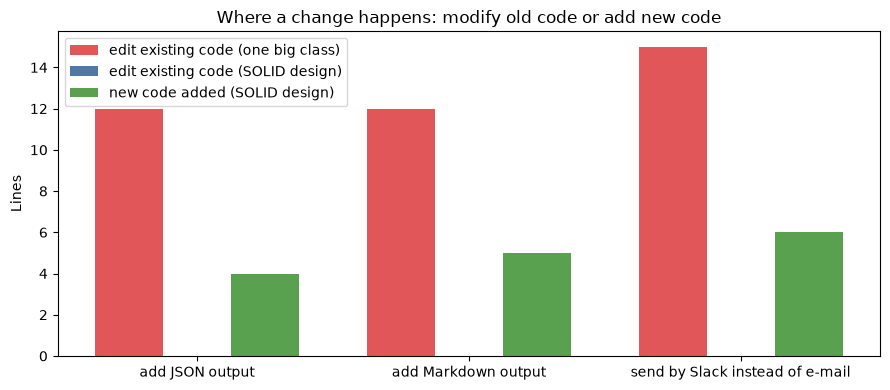

In [7]:
import matplotlib.pyplot as plt

changes = ["add JSON output", "add Markdown output", "send by Slack instead of e-mail"]
monolith_edits = [12, 12, 15]     # lines of the existing run() method that change (estimated from the code above)
solid_edits = [0, 0, 0]           # existing classes unchanged: add one new class each time
new_code = [4, 5, 6]              # lines of the new class

fig, ax = plt.subplots(figsize=(9, 4))
x = range(len(changes))
ax.bar([i - 0.25 for i in x], monolith_edits, width=0.25, color="#E15759", label="edit existing code (one big class)")
ax.bar(list(x), solid_edits, width=0.25, color="#4E79A7", label="edit existing code (SOLID design)")
ax.bar([i + 0.25 for i in x], new_code, width=0.25, color="#59A14F", label="new code added (SOLID design)")
ax.set_xticks(list(x), changes)
ax.set(title="Where a change happens: modify old code or add new code", ylabel="Lines")
ax.legend()
plt.tight_layout()
plt.show()

The chart summarises the idea (the line counts are estimates from the code in this lesson): with SOLID, new requirements add new, small classes, and the tested classes stay untouched.

*Insight: Apply SOLID when you feel pain: a class that changes for many reasons, a growing `if/elif` chain of types, or code that you cannot test without a real database. For a 50-line script, extra abstractions only add complexity.*

## Real-World Use Case or Analogy

SOLID is like the design of **electrical plugs and sockets**. The socket (an interface) does not care which device you plug in (Liskov, dependency inversion). You add a new device without rewiring the house (open/closed). A lamp does not need the three-phase socket of an oven (interface segregation). And the fuse box, the wiring and the lamps are separate parts that an electrician can replace one by one (single responsibility).

ML frameworks follow these principles: scikit-learn estimators share a small `fit/predict` interface, PyTorch Lightning injects loggers and callbacks, and LangChain lets you swap the LLM provider without changing the chain.